In [1]:
import glob
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import cmocean
import numpy as np
import xarray as xr

TODO:
- Use the "change cat" files to see if the landing page will look different.
- Calculate the change from baseline instead of plotting the absolute values (as currently below)


In [2]:
variables_dict = {
    'cherry-fruit-cracking-days-at-maturity': 'cherry-fruit-cracking-days-at-maturity',
    'general-average-summer-temperature': 'tavg',
    'general-average-winter-temperature': 'tavg',
#    'general-drought-baseline-thresholds': '',
    'general-drought-intensity': 'drought_intensity',
#    'general-historical-drought-events': '',
#    'general-historical-hot-dry-events': '',
    'general-hot-days': 'general-hot-days',
#	'general-hot-dry-events-baseline-thresholds': '',
	'general-time-in-drought': 'time_in_drought',
	'general-time-in-hot-dry-events': 'time_in_hot_dry_events',
	'mango-wet-days-at-harvest': 'mango-wet-days-at-harvest',
	'northern-beef-dry-season-rainfall': 'precip',
	'northern-beef-wet-season-rainfall': 'precip',
	'potato-frost-days-at-tuber-initiation': 'potato-frost-days-at-tuber-initiation',
# summer reference evapotranspiration?
}

#cmip6_to_cmip5_time = {}
#cmip6_to_cmip5_time['2035-2064'] = '2036-2065'
#cmip6_to_cmip5_time['2070-2099'] = '2056-2085'
                         
cmip6_to_cmip5_experiment = {}
cmip6_to_cmip5_experiment['ssp245'] = 'rcp45'
cmip6_to_cmip5_experiment['ssp370'] = 'rcp85'

In [143]:
def plot_comparison(variable, cmip6_exp, var_levels, diff_levels, cmap, extend='max'):
    """Plot comparison between CMIP6 and CMIP5"""

    file_var = variables_dict[variable]
    cmip5_exp = cmip6_to_cmip5_experiment[cmip6_exp]
    
    base_dir = '/Volumes/{d61-csa-p2}/work/CSA/Science/Data/cmip6-transition-data/'
    cmip6_mid_file = glob.glob(f'{base_dir}/{variable}/netcdf/{variable}-cmip6-2035-2064-{cmip6_exp}*mmm-avg.nc')[0]
    cmip5_mid_file = glob.glob(f'{base_dir}/{variable}/netcdf/{variable}-cmip5-2036-2065-{cmip5_exp}*mmm-avg.nc')[0]
    cmip6_late_file = glob.glob(f'{base_dir}/{variable}/netcdf/{variable}-cmip6-2070-2099-{cmip6_exp}*mmm-avg.nc')[0]
    cmip5_late_file = glob.glob(f'{base_dir}/{variable}/netcdf/{variable}-cmip5-2056-2085-{cmip5_exp}*mmm-avg.nc')[0]

    cmip6_mid_da = xr.open_dataset(cmip6_mid_file, decode_times=False)[file_var]
    cmip5_mid_da = xr.open_dataset(cmip5_mid_file, decode_times=False)[file_var]
    cmip6_late_da = xr.open_dataset(cmip6_late_file, decode_times=False)[file_var]
    cmip5_late_da = xr.open_dataset(cmip5_late_file, decode_times=False)[file_var]

    fig = plt.figure(figsize=[10, 10])
    
    units = cmip6_mid_da.attrs['units']
    cbar_pad = 0.04
    
    ax1 = fig.add_subplot(231, projection=ccrs.PlateCarree())
    cmip6_mid_da.plot(
        ax=ax1,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax1.set_title(f'CMIP6 (2035-2064, {cmip6_exp})')
    
    ax2 = fig.add_subplot(232, projection=ccrs.PlateCarree())
    cmip5_mid_da.plot(
        ax=ax2,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax2.set_title(f'CMIP5 (2036-2065, {cmip5_exp})')
    
    diff_mid = cmip6_mid_da - cmip5_mid_da
    ax3 = fig.add_subplot(233, projection=ccrs.PlateCarree())
    diff_mid.plot(
        ax=ax3,
        transform=ccrs.PlateCarree(),
        levels=diff_levels,
        extend='both',
        cmap='RdBu_r',
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax3.set_title('Difference (CMIP6 - CMIP5)')

    ax4 = fig.add_subplot(234, projection=ccrs.PlateCarree())
    cmip6_late_da.plot(
        ax=ax4,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax4.set_title(f'CMIP6 (2070-2099, {cmip6_exp})')
    
    ax5 = fig.add_subplot(235, projection=ccrs.PlateCarree())
    cmip5_late_da.plot(
        ax=ax5,
        transform=ccrs.PlateCarree(),
        levels=var_levels,
        extend=extend,
        cmap=cmap,
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax5.set_title(f'CMIP5 (2056-2085, {cmip5_exp})')
    
    diff_late = cmip6_late_da - cmip5_late_da
    ax6 = fig.add_subplot(236, projection=ccrs.PlateCarree())
    diff_late.plot(
        ax=ax6,
        transform=ccrs.PlateCarree(),
        levels=diff_levels,
        extend='both',
        cmap='RdBu_r',
        cbar_kwargs={'label': units, 'location': 'bottom', 'pad': cbar_pad},
    )
    ax6.set_title('Difference (CMIP6 - CMIP5)')
    
    for ax in [ax1, ax2, ax3, ax4, ax5, ax6]:
        ax.coastlines()
        ax.add_feature(cartopy.feature.STATES)
    #    gls = ax.gridlines(linestyle="--", draw_labels=True)
    #    gls.top_labels = False
    #    gls.right_labels = False
    #    ax.tick_params(axis='y', labelleft=False)

    fig.subplots_adjust(hspace=0) 
    plt.suptitle(f'{variable} (multi-model mean)', y=0.85)
    plt.tight_layout()
    plt.show()

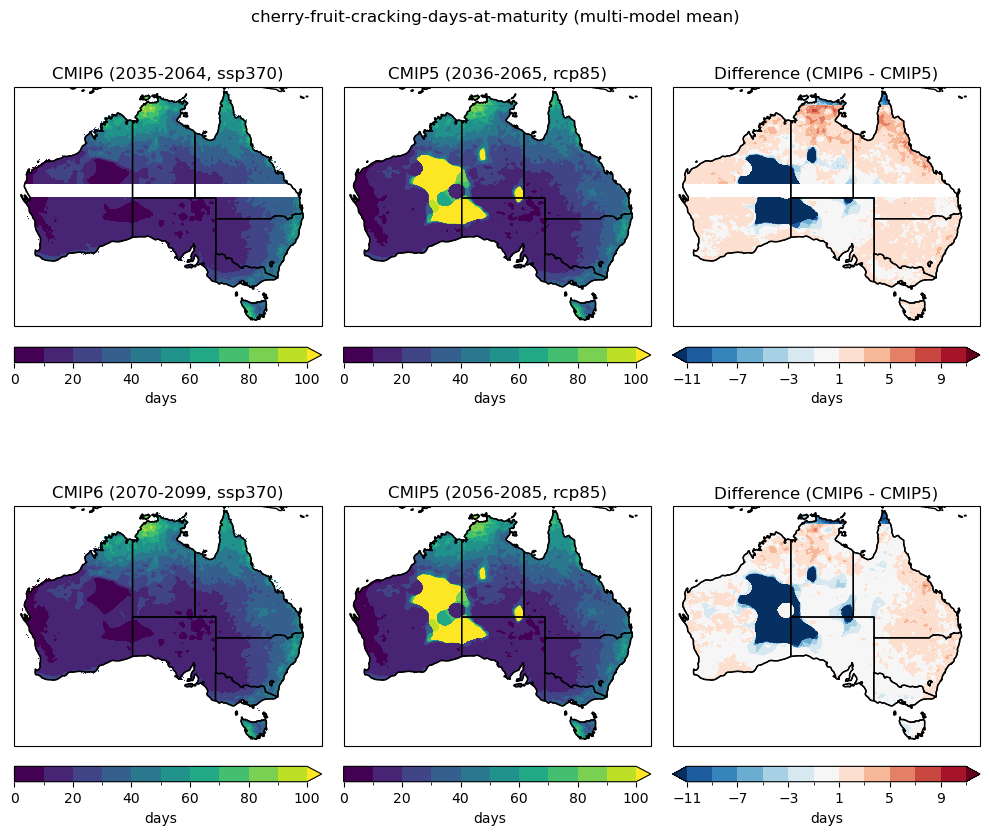

In [144]:
plot_comparison(
    'cherry-fruit-cracking-days-at-maturity',
    'ssp370',
    np.arange(0, 101, 10),
    np.arange(-11, 12, 2),
    'viridis'
)

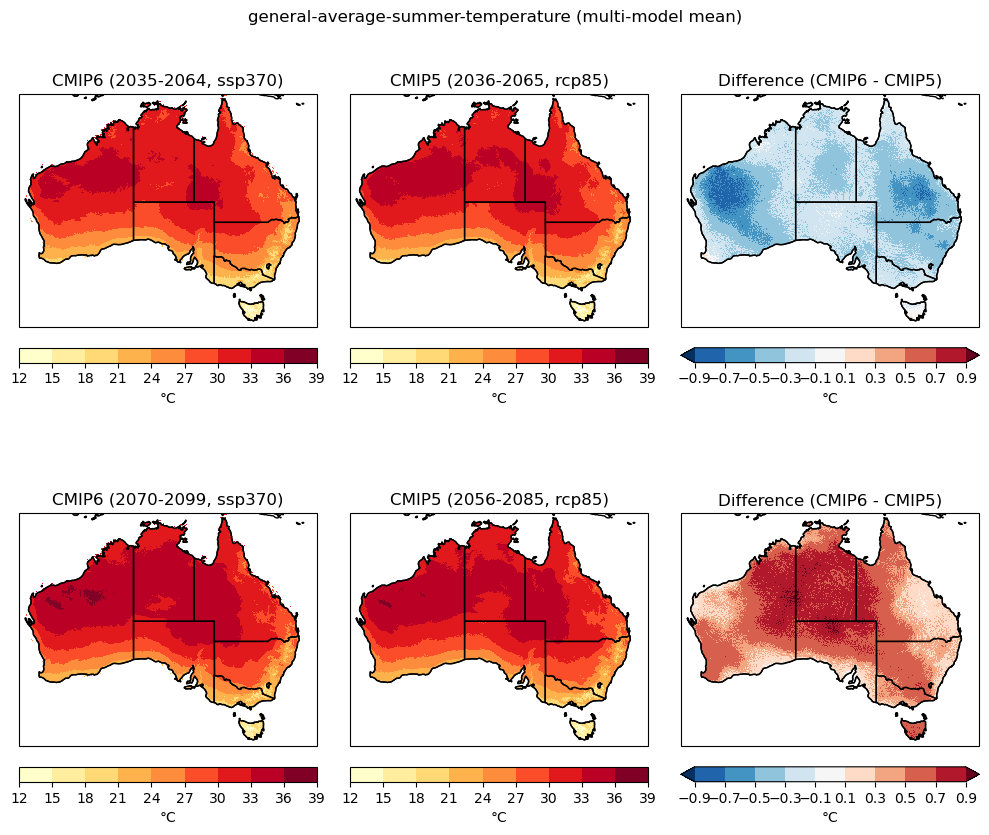

In [145]:
plot_comparison(
    'general-average-summer-temperature',
    'ssp370',
    np.arange(12, 41, 3),
    [-0.9, -0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7, 0.9],
    'YlOrRd',
    extend='neither'
)

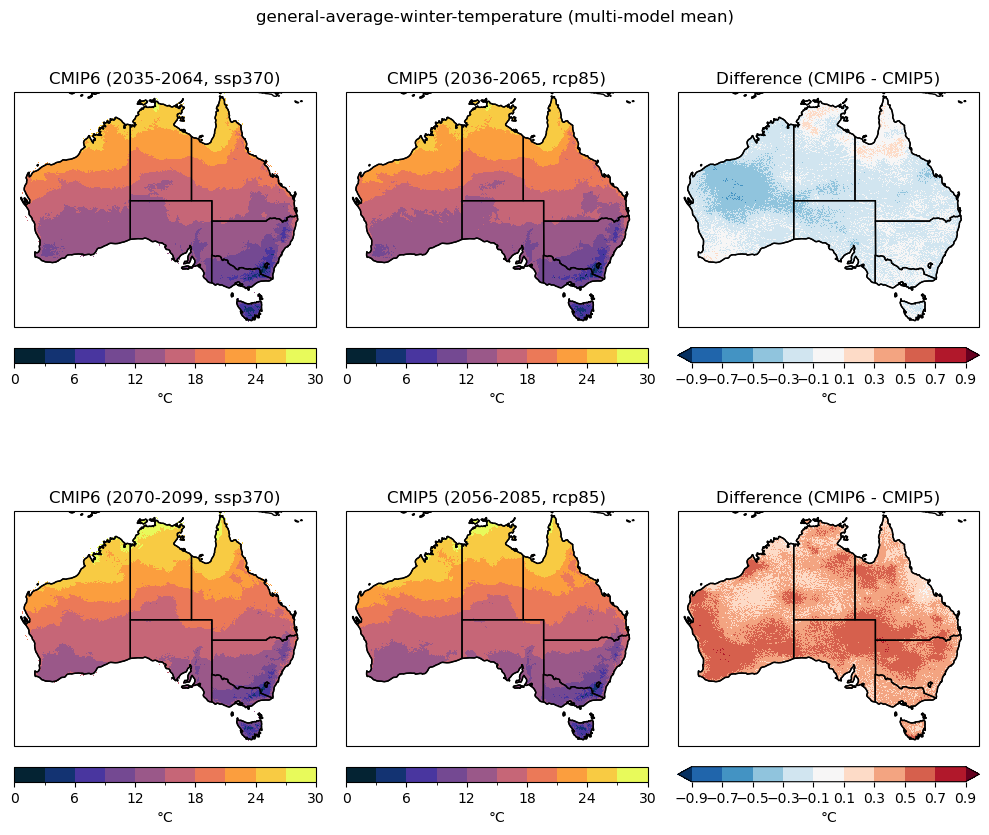

In [146]:
plot_comparison(
    'general-average-winter-temperature',
    'ssp370',
    np.arange(0, 31, 3),
    [-0.9, -0.7, -0.5, -0.3, -0.1, 0.1, 0.3, 0.5, 0.7, 0.9],
    cmocean.cm.thermal,
    extend='neither'
)

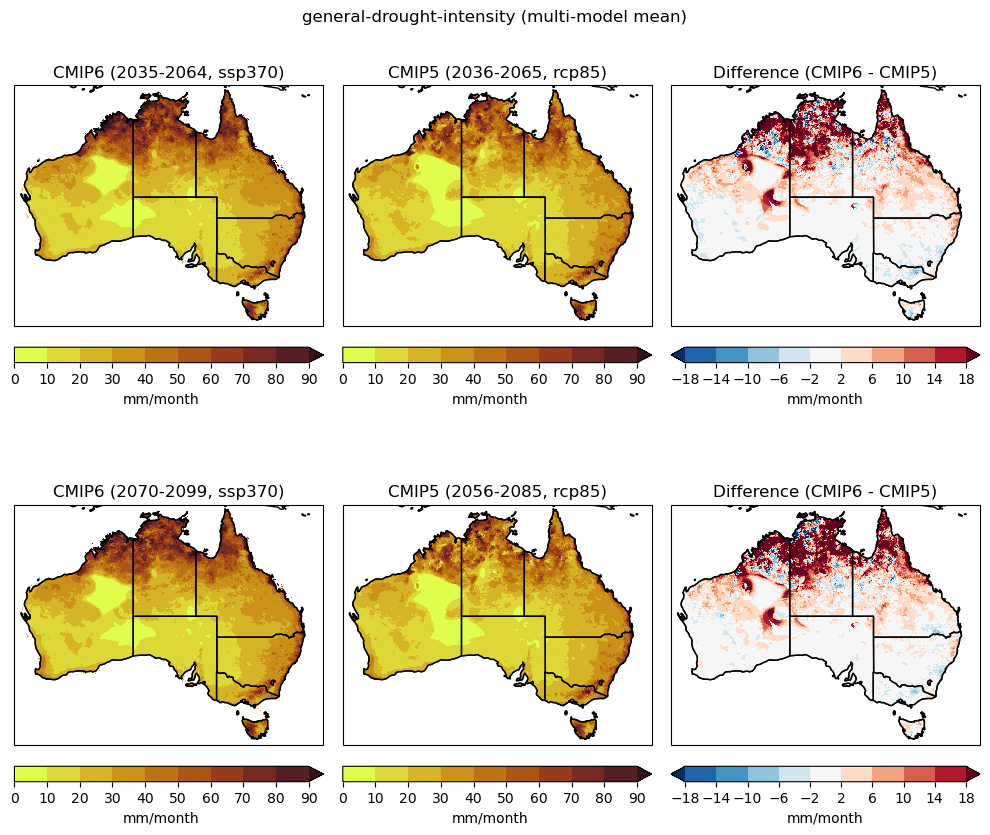

In [147]:
plot_comparison(
    'general-drought-intensity',
    'ssp370',
    np.arange(0, 100, 10),
    np.arange(-18, 19, 4),
    cmocean.cm.solar_r,
    extend='max'
)

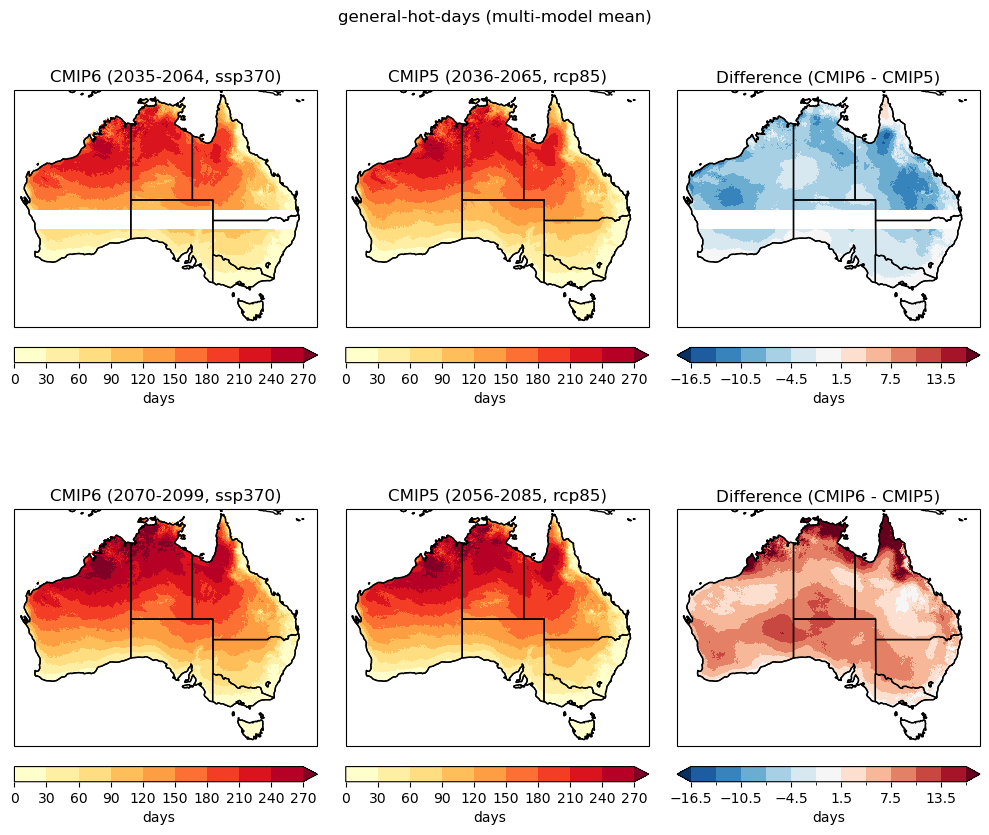

In [148]:
plot_comparison(
    'general-hot-days',
    'ssp370',
    np.arange(0, 300, 30),
    np.arange(-16.5, 17, 3),
    'YlOrRd'
)

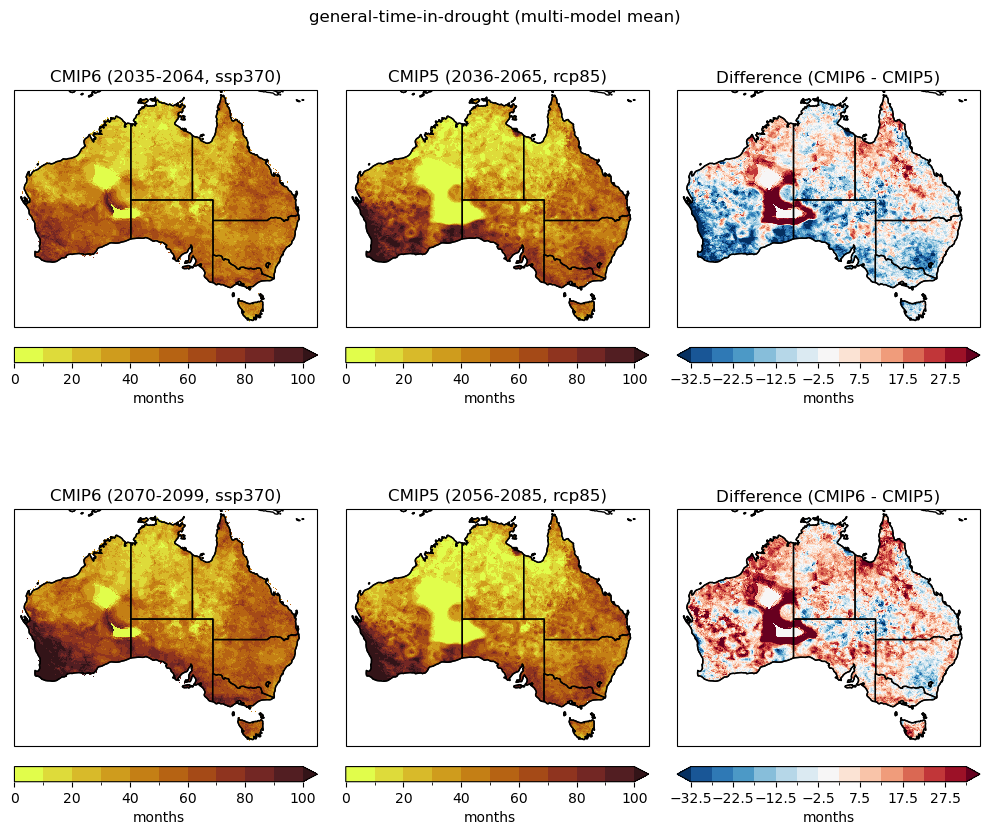

In [149]:
plot_comparison(
    'general-time-in-drought',
    'ssp370',
    np.arange(0, 101, 10),
    np.arange(-32.5, 33, 5),
    cmocean.cm.solar_r
)

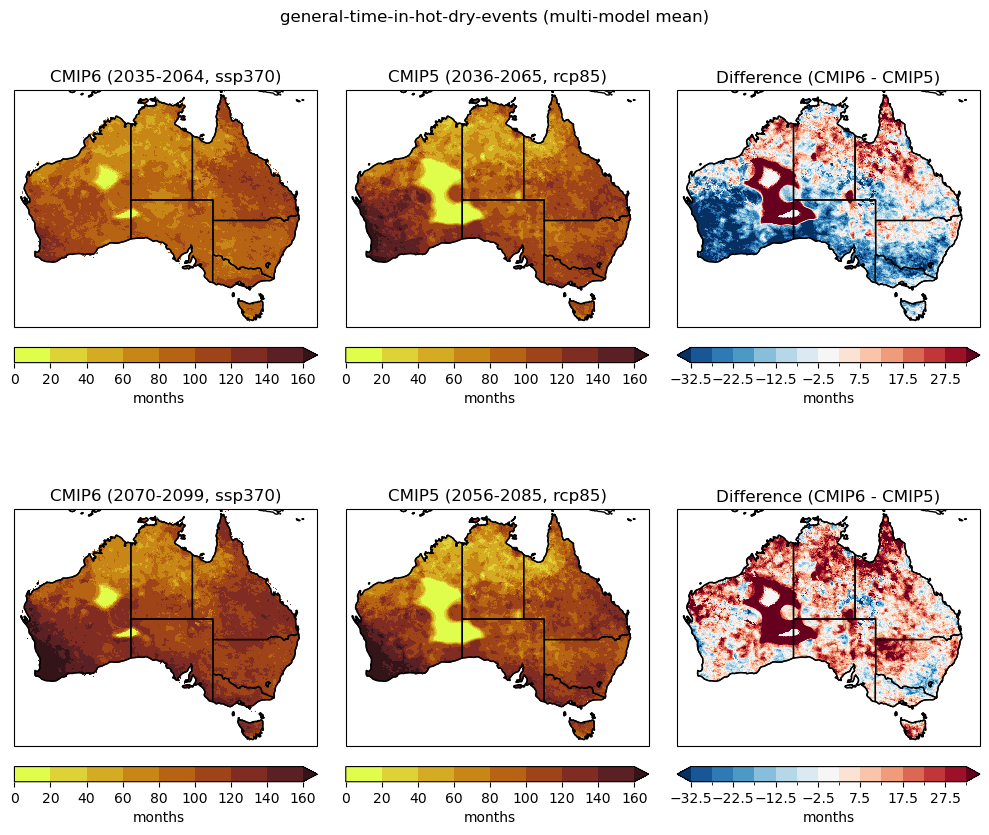

In [150]:
plot_comparison(
    'general-time-in-hot-dry-events',
    'ssp370',
    np.arange(0, 180, 20),
    np.arange(-32.5, 33, 5),
    cmocean.cm.solar_r
)